In [72]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core
from hnn_core.externals.mne import tfr_array_morlet
from hnn_core.viz import plot_tfr_morlet
from hnn_core import MPIBackend, JoblibBackend, average_dipoles

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from general_plot_utils import assign_color

from hnn_core import duecker_ET_model, simulate_dipole
import matplotlib.pyplot as plt
import numpy as np

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/gamma'
os.makedirs(pathfig, exist_ok=True)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42


In [3]:
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET.json')
params = hnn_core.read_params(params_fname)

In [12]:
seed = np.random.randint(0, 1e6)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0045, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

In [13]:
with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

Text(0.5, 0, 'frequency (Hz)')

/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


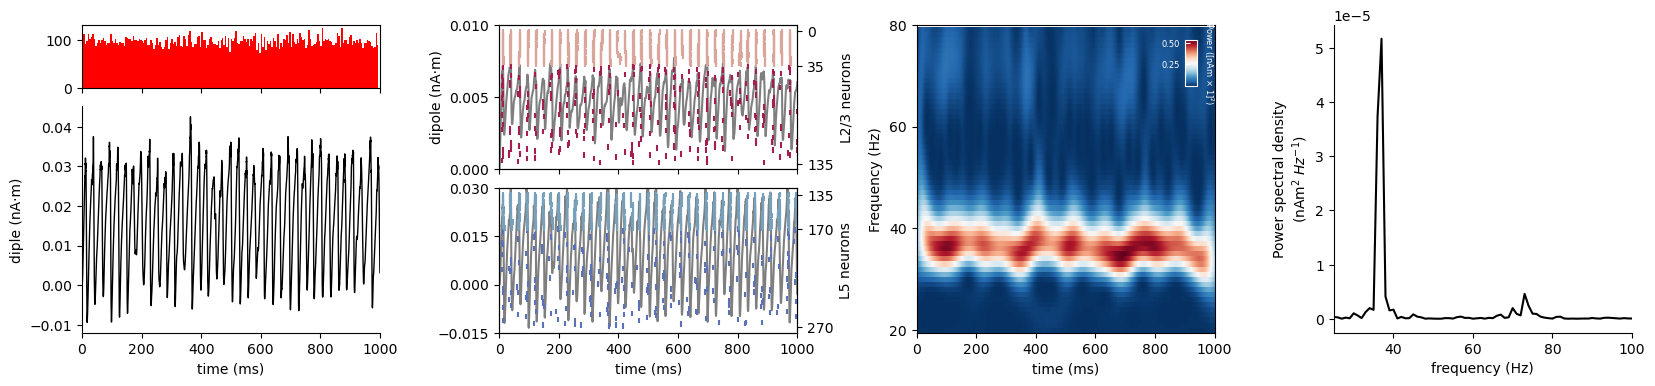

In [ ]:
from matplotlib import gridspec
fig = plt.figure(constrained_layout=True, figsize=(20,4))

gs = fig.add_gridspec(4,4, height_ratios=[.25, 0.25, 0.25, 0.25], hspace=0.3, wspace=.4)
ax00 = fig.add_subplot(gs[0,0])
ax10 = fig.add_subplot(gs[1:4,0])
ax11 = fig.add_subplot(gs[0:2,1])
ax21 = fig.add_subplot(gs[2:,1])
ax3 = fig.add_subplot(gs[:,2])
ax4 = fig.add_subplot(gs[:,3])

# drives
bins = np.arange(0, 1000, 5)
spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

ax00.hist(spike_prox1, bins=bins, color='r')
ax00.set_xlim([0, 1000])
ax00.set_xticklabels([])            
# dipole
ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
ax10.set_ylabel('diple (nA·m)')
ax10.set_xlim([0, 1000])
ax10.spines['top'].set_visible(False)
ax10.spines['right'].set_visible(False)
ax10.set_xlabel('time (ms)')

# dipole and raster
I = np.array(net.cell_response.spike_gids[0]) < 135
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.5)
ax11.set_ylim([0, 0.01])
ax11.set_xlim([0, 1000])
ax11.set_ylabel('dipole (nA·m)')
ax11.set_yticks([0.0, 0.005, 0.01])
ax12 = ax11.twinx()

ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax12.set_ylabel('L2/3 neurons')
ax12.set_xticklabels([])
ax12.invert_yaxis()
ax12.set_yticks([0, 35, 135])


I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.5)
ax21.set_xlim([0, 1000])
ax21.set_ylim([-0.015, 0.03])
ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
ax22 = ax21.twinx()
ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax22.set_ylabel('L5 neurons')
ax22.invert_yaxis()
ax22.set_yticks([135, 170, 270])
ax21.set_xlabel('time (ms)')

# TFR
freqs = np.arange(20, 80, 1)
dpl[0].plot_tfr_morlet(freqs, ax=ax3, n_cycles=7, show=False, colormap='RdBu_r', colorbar_inside=True)
ax3.set_xlabel('time (ms)')
ax3.set_yticks([20, 40, 60, 80])
ax3.set_xlim([0, 1000])

# PSD
dpl[0].plot_psd(ax=ax4, fmin=25, fmax=100, show=False, color='k')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.set_xlabel('frequency (Hz)')

fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained.pdf'))

In [78]:
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET_bursty.json')
params = hnn_core.read_params(params_fname)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0045, 'L5_pyramidal': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5_pyramidal': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=10)

MPI will run 10 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading c

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_10092/2298215953.py:76: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


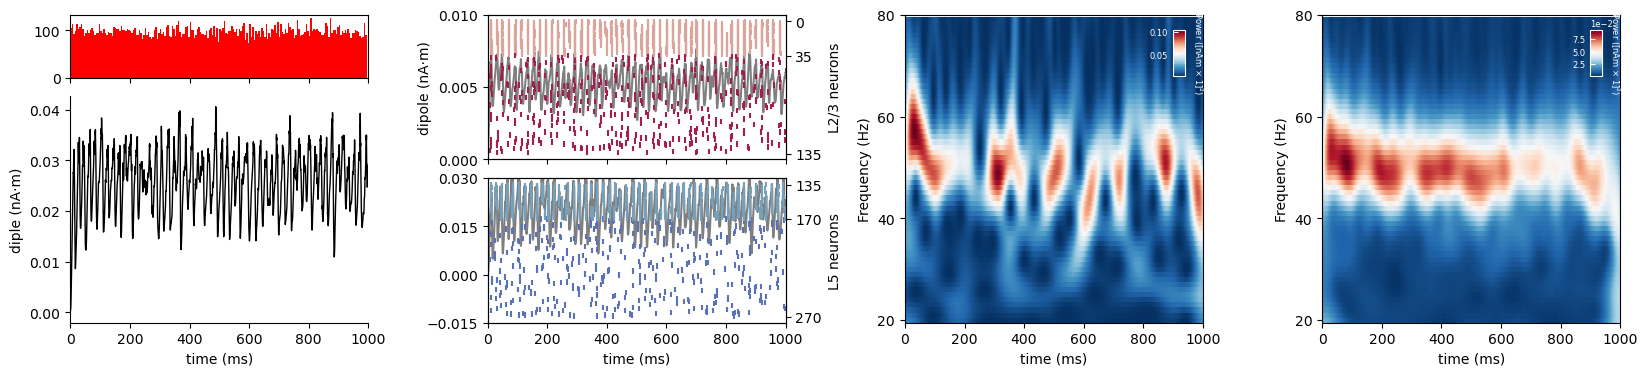

In [ ]:
fig = plt.figure(constrained_layout=True, figsize=(20,4))

gs = fig.add_gridspec(4,4, height_ratios=[.25, 0.25, 0.25, 0.25], hspace=0.3, wspace=.4)
ax00 = fig.add_subplot(gs[0,0])
ax10 = fig.add_subplot(gs[1:4,0])
ax11 = fig.add_subplot(gs[0:2,1])
ax21 = fig.add_subplot(gs[2:,1])
ax3 = fig.add_subplot(gs[:,2])
ax4 = fig.add_subplot(gs[:,3])

# drives
bins = np.arange(0, 1000, 5)
spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

ax00.hist(spike_prox1, bins=bins, color='r')
ax00.set_xlim([0, 1000])
ax00.set_xticklabels([])            
# dipole
ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
ax10.set_ylabel('diple (nA·m)')
ax10.set_xlim([0, 1000])
ax10.spines['top'].set_visible(False)
ax10.spines['right'].set_visible(False)
ax10.set_xlabel('time (ms)')

# dipole and raster
I = np.array(net.cell_response.spike_gids[0]) < 135
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.5)
ax11.set_ylim([0, 0.01])
ax11.set_xlim([0, 1000])
ax11.set_ylabel('dipole (nA·m)')
ax11.set_yticks([0.0, 0.005, 0.01])
ax12 = ax11.twinx()

ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax12.set_ylabel('L2/3 neurons')
ax12.set_xticklabels([])
ax12.invert_yaxis()
ax12.set_yticks([0, 35, 135])


I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
colors = [assign_color(net, gid) for gid in gids]

ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.5)
ax21.set_xlim([0, 1000])
ax21.set_ylim([-0.015, 0.03])
ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
ax22 = ax21.twinx()
ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
ax22.set_ylabel('L5 neurons')
ax22.invert_yaxis()
ax22.set_yticks([135, 170, 270])
ax21.set_xlabel('time (ms)')

# TFR
freqs = np.arange(20, 80, 1)
dpl[0].plot_tfr_morlet(freqs, ax=ax3, n_cycles=7, show=False, colormap='RdBu_r', colorbar_inside=True)
ax3.set_xlabel('time (ms)')
ax3.set_yticks([20, 40, 60, 80])
ax3.set_xlim([0, 1000])

# TFR average
plot_tfr_morlet(dpl, freqs, ax=ax4, n_cycles=7, show=False, colormap='RdBu_r', colorbar_inside=True)
ax4.set_xlabel('time (ms)')
ax4.set_yticks([20, 40, 60, 80])
ax4.set_xlim([0, 1000])


fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))